In [1]:

!pip install -q imbalanced-learn


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

from google.colab import files

uploaded = files.upload()


Saving data (1).csv to data (1).csv


In [10]:

df = pd.read_csv("data (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (1200, 14)


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [11]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nOrder status counts:")
print(df["OrderStatus"].value_counts(dropna=False))


Column names:
['OrderID', 'Date', 'CustomerID', 'Product', 'Quantity', 'UnitPrice', 'ShippingAddress', 'PaymentMethod', 'OrderStatus', 'TrackingNumber', 'ItemsInCart', 'CouponCode', 'ReferralSource', 'TotalPrice']

Missing values in each column:
OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

Duplicate rows: 0

Order status counts:
OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64


In [12]:

df = df.drop_duplicates().copy()

# Convert the date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Extract useful date features
df["OrderMonth"] = df["Date"].dt.month
df["OrderDay"] = df["Date"].dt.day
df["OrderWeekday"] = df["Date"].dt.dayofweek

# Remove identifiers and address/tracking information
df = df.drop(
    columns=[
        "OrderID",
        "CustomerID",
        "ShippingAddress",
        "TrackingNumber",
        "Date"
    ],
    errors="ignore"
)

# Replace missing coupon values
df["CouponCode"] = df["CouponCode"].fillna("No Coupon")

# Remove rows with a missing target
df = df.dropna(subset=["OrderStatus"])

print("Cleaned dataset shape:", df.shape)
display(df.head())


Cleaned dataset shape: (1200, 12)


,Product,Quantity,UnitPrice,PaymentMethod,OrderStatus,ItemsInCart,CouponCode,ReferralSource,TotalPrice,OrderMonth,OrderDay,OrderWeekday
0,Monitor,5,570.62,Debit Card,Shipped,7,SAVE10,Instagram,2853.10,1,4,2
1,Phone,2,151.35,Online,Shipped,3,SAVE10,Referral,302.70,8,23,4
2,Tablet,5,550.68,Credit Card,Cancelled,8,FREESHIP,Email,2753.40,2,27,1
3,Chair,1,273.19,Debit Card,Returned,5,SAVE10,Facebook,273.19,10,15,6
4,Printer,4,626.01,Online,Delivered,8,SAVE10,Email,2504.04,5,8,3


In [13]:

X = df.drop(columns=["OrderStatus"])
y = df["OrderStatus"].astype(str)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())


Features shape: (1200, 11)
Target shape: (1200,)

Target classes:
OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64


In [14]:

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)


Numerical columns:
['Quantity', 'UnitPrice', 'ItemsInCart', 'TotalPrice', 'OrderMonth', 'OrderDay', 'OrderWeekday']

Categorical columns:
['Product', 'PaymentMethod', 'CouponCode', 'ReferralSource']


In [15]:

numeric_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = SklearnPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [16]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())


Training records: 960
Testing records: 240

Training class distribution:
OrderStatus
Cancelled    200
Returned     197
Pending      190
Shipped      188
Delivered    185
Name: count, dtype: int64


In [17]:

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [18]:

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [19]:

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)

print("LOGISTIC REGRESSION RESULTS")

print("\nPrecision:")
print(precision_score(
    y_test, y_pred_lr,
    average="weighted",
    zero_division=0
))

print("\nRecall:")
print(recall_score(
    y_test, y_pred_lr,
    average="weighted",
    zero_division=0
))

print("\nROC-AUC:")
print(roc_auc_score(
    y_test,
    y_prob_lr,
    labels=logistic_model.named_steps["classifier"].classes_,
    multi_class="ovr",
    average="weighted"
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_lr, zero_division=0
))


LOGISTIC REGRESSION RESULTS

Precision:
0.21193849372107518

Recall:
0.21666666666666667

ROC-AUC:
0.5069100794023411

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.25      0.18      0.21        50
   Delivered       0.25      0.35      0.29        46
     Pending       0.24      0.28      0.26        47
    Returned       0.18      0.18      0.18        50
     Shipped       0.13      0.11      0.12        47

    accuracy                           0.22       240
   macro avg       0.21      0.22      0.21       240
weighted avg       0.21      0.22      0.21       240



In [20]:

y_pred_rf = forest_model.predict(X_test)
y_prob_rf = forest_model.predict_proba(X_test)

print("RANDOM FOREST RESULTS")

print("\nPrecision:")
print(precision_score(
    y_test, y_pred_rf,
    average="weighted",
    zero_division=0
))

print("\nRecall:")
print(recall_score(
    y_test, y_pred_rf,
    average="weighted",
    zero_division=0
))

print("\nROC-AUC:")
print(roc_auc_score(
    y_test,
    y_prob_rf,
    labels=forest_model.named_steps["classifier"].classes_,
    multi_class="ovr",
    average="weighted"
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf, zero_division=0
))


RANDOM FOREST RESULTS

Precision:
0.1780455149903288

Recall:
0.18333333333333332

ROC-AUC:
0.4902220662695144

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.16      0.18      0.17        50
   Delivered       0.17      0.17      0.17        46
     Pending       0.23      0.32      0.27        47
    Returned       0.16      0.10      0.12        50
     Shipped       0.17      0.15      0.16        47

    accuracy                           0.18       240
   macro avg       0.18      0.18      0.18       240
weighted avg       0.18      0.18      0.18       240



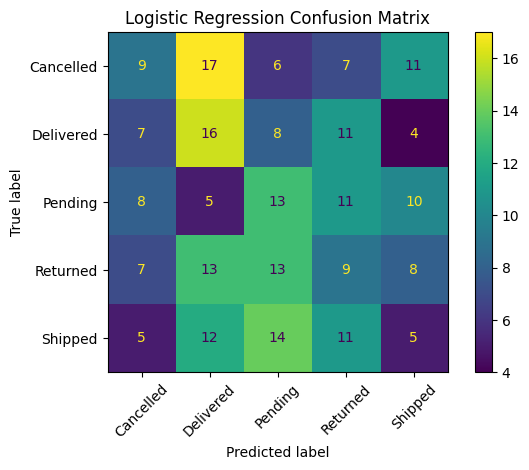

In [21]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    xticks_rotation=45
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()


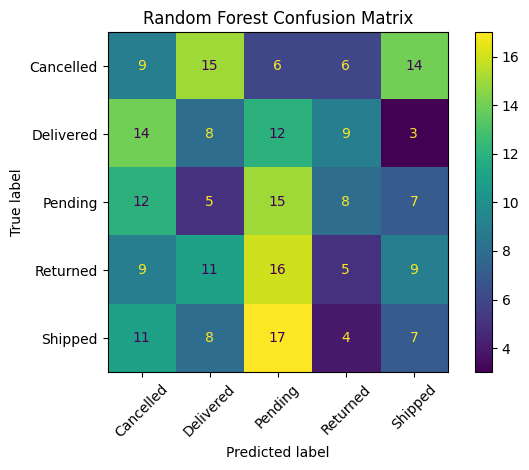

In [22]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


In [23]:

results = []

for name, model, predictions, probabilities in [
    ("Logistic Regression", logistic_model, y_pred_lr, y_prob_lr),
    ("Random Forest", forest_model, y_pred_rf, y_prob_rf)
]:
    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities,
            labels=model.named_steps["classifier"].classes_,
            multi_class="ovr",
            average="weighted"
        )
    })

results_df = pd.DataFrame(results)

display(results_df)


,Model,Precision,Recall,ROC-AUC
0,Logistic Regression,0.211938,0.216667,0.506910
1,Random Forest,0.178046,0.183333,0.490222


In [24]:

tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(max_iter=2000))
])

param_grid = {
    "classifier__C": [0.1, 1, 10]
}

grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid,
    scoring="roc_auc_ovr_weighted",
    cv=3,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(grid_search.best_score_)


Best parameters:
{'classifier__C': 10}

Best cross-validation ROC-AUC:
0.49898063113345276


In [25]:

best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)
tuned_probabilities = best_model.predict_proba(X_test)

print("TUNED LOGISTIC REGRESSION")

print("\nPrecision:")
print(precision_score(
    y_test, tuned_predictions,
    average="weighted",
    zero_division=0
))

print("\nRecall:")
print(recall_score(
    y_test, tuned_predictions,
    average="weighted",
    zero_division=0
))

print("\nROC-AUC:")
print(roc_auc_score(
    y_test,
    tuned_probabilities,
    labels=best_model.named_steps["classifier"].classes_,
    multi_class="ovr",
    average="weighted"
))

print("\nClassification Report:")
print(classification_report(
    y_test, tuned_predictions,
    zero_division=0
))


TUNED LOGISTIC REGRESSION

Precision:
0.20909572987707498

Recall:
0.2125

ROC-AUC:
0.5068863268756262

Classification Report:
              precision    recall  f1-score   support

   Cancelled       0.25      0.18      0.21        50
   Delivered       0.24      0.33      0.28        46
     Pending       0.25      0.28      0.26        47
    Returned       0.18      0.18      0.18        50
     Shipped       0.13      0.11      0.12        47

    accuracy                           0.21       240
   macro avg       0.21      0.21      0.21       240
weighted avg       0.21      0.21      0.21       240



In [26]:

results_df.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")
display(results_df)


Model comparison saved successfully!


,Model,Precision,Recall,ROC-AUC
0,Logistic Regression,0.211938,0.216667,0.506910
1,Random Forest,0.178046,0.183333,0.490222


In [27]:

from google.colab import files

files.download("model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>